In [1]:
import torch
import torch.nn as nn
from tqdm import tqdm
import scipy.io as io

from src.utils import utils, plots
from src.models import foundation_models as hfm, unmixers as unmx

dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.set_default_device(dev)
print(f"Using device: {dev}")

/home/ids/edabier/miniconda3/envs/hsu-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda:0


### Configuration:
- Choose the **dataset** on which to perform unixming (Samson, Jasper, Apex or Urban)
- Choose the **HFM** you want to use (SpecAware, DOFA, SpecViT, Panopticon, HyperSIGMA, HyperSL, HyperFree, UniverSat)
- Use the correct format for wavelengths (**μm** for DOFA and UniverSat, **nm** for the others)
- Configure the training (epochs, lr, weight_decay, n_xp)

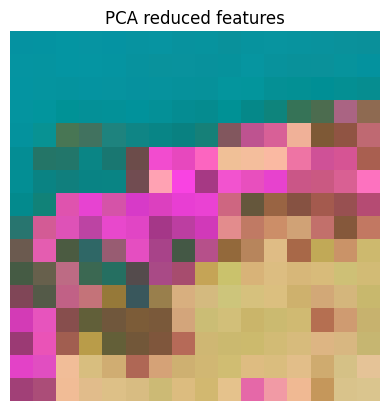

In [2]:
dataset = "samson"
fm_name = "UniverSat"
epochs, lr, weight_decay, n_xp = 200, 0.002, 0.18, 10

data = io.loadmat(f"data/{dataset}.mat")
Y_init = utils.oneD_to_2d(torch.tensor(data["Y"], dtype=torch.float)).unsqueeze(0)
A_init = utils.oneD_to_2d(torch.tensor(data["A"], dtype=torch.float)).unsqueeze(0)
E_init = torch.tensor(data["E"], dtype=torch.float)
B, c, H = E_init.shape[0], E_init.shape[1], Y_init.shape[-1]

wavelengths_path = f"data/{dataset}_wavelength_μm.txt" # Use for DOFA and UniverSat
# wavelengths_path = f"data/{dataset}_wavelength.txt" # Use for other HFMs
with open(wavelengths_path, "r") as file:
    lines = file.readlines()
    wavelengths = [float(line.strip()) for line in lines if line.strip()]

fm, Y_init_f, new_H = hfm.instantiate_fm(fm_name, Y_init)
with torch.no_grad():
    _, features = hfm.extract_f(fm, Y_init, new_H, wavelengths, patch_size=16)

D = int(features.shape[0])
alpha = int(features.shape[1]**0.5)
plots.plot_pca_features(features)

In [ ]:
mses, sads = [], []
loader, _ = utils.create_dataloader(dataset, device=dev)
E_hats, A_hats = torch.zeros(n_xp, B, c), torch.zeros(n_xp, c, new_H, new_H)

for i in tqdm(range(n_xp)):
    print(f"training {i+1}/{n_xp}")

    model = unmx.UnmixingFromFeatures(D=D, alpha=alpha, H=new_H, B=B, c=c)
    model.apply(model.weights_init)
    model = unmx.init_decoder_weights(model, Y_init_f/Y_init_f.max(), c)

    optimizer = torch.optim.AdamW(params=model.parameters(), lr=lr, weight_decay=weight_decay)

    for _ in range(epochs):

        for Y, E, A in loader:
        
            optimizer.zero_grad()

            _, features = hfm.extract_f(fm, Y, new_H, wavelengths)

            E_hat, A_hat, Y_hat = model(features, Y)

            loss = model.loss(Y, Y_hat, A_hat)
            loss.backward()
            
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=10, norm_type=1)
            optimizer.step()
    
    model.eval()
    with torch.no_grad():
        
        _, features = hfm.extract_f(fm, Y, new_H, wavelengths)
        E_hat, A_hat, _ = model(features, Y)

        sad, _, mse = plots.compute_metrics_and_plot(E_hat, A_hat, A, E, return_results=True, plot_E=False, plot_A=False)
        print(f"Current SAD = {format(sad, '.3f')}, NMSE = {format(mse, '.3f')}")
        mses.append(mse)
        sads.append(sad)
    E_hats[i] = E_hat
    A_hats[i] = A_hat

# Ensembling for even better performances:
E_hat_m = torch.nanmean(E_hats, dim=0)
A_hat_m = torch.nanmean(A_hats, dim=0)   
plots.compute_metrics_and_plot(E_hat_m, A_hat_m, A, E)

print(f"Average SAD = {format(torch.mean(torch.tensor(sads)), '.3f')} ± {format(torch.std(torch.tensor(sads)), '.2f')}, NMSE = {format(torch.mean(torch.tensor(mses)), '.3f')} ± {format(torch.std(torch.tensor(mses)), '.2f')}")